# Cartera dedicada · Índices

**Objetivo.** Medir la exposición a índices bursátiles con instrumentos invertibles, sin el riesgo
idiosincrático de una sola empresa.

- **Universo:** cinco ETF estadounidenses que replican índices: `SPY` (S&P 500), `QQQ` (Nasdaq 100),
  `IWM` (Russell 2000), `EFA` (mercados desarrollados fuera de EE. UU.) y `EEM` (mercados emergentes).
- **Moneda:** USD. La biblioteca no convierte divisas, así que todos los ejemplos usan una sola moneda.
- **Ventana:** desde `2025-01-02` hasta la última sesión disponible.
- **Anualización:** 252 sesiones.

Los niveles de índice (`^GSPC`, `^IBEX`, etc.) no son invertibles directamente; por eso la cartera usa
ETF que los replican. El cuaderno principal conserva los niveles como series de referencia.

Datos hasta la última sesión disponible anterior a `END` (2026-11-06).

In [1]:
"""Cartera dedicada de índices: ingesta, informe y simulación."""

import warnings

from IPython.display import Markdown

from quantfolio import (
    CachedPriceSource,
    MonteCarloParameters,
    Portfolio,
    YahooFinanceSource,
)

#: yfinance todavía usa argumentos ``inplace`` que pandas 3 marca como obsoletos.
warnings.filterwarnings("ignore", message=".*inplace keyword.*")

START = "2025-01-02"
END = "2026-11-06"
TICKERS = ["SPY", "QQQ", "IWM", "EFA", "EEM"]
WEIGHTS = {"SPY": 0.20, "QQQ": 0.20, "IWM": 0.20, "EFA": 0.20, "EEM": 0.20}
PERIODS_PER_YEAR = 252

## 1 · Ingesta

Los ETF se descargan con `get_many()` y se normalizan en `PriceSeries`. La caché CSV evita repetir
la descarga mientras los datos sigan siendo recientes. `auto_adjust=True` incorpora los dividendos
al precio, de modo que la serie se aproxima a la rentabilidad total del ETF.

In [2]:
source = CachedPriceSource(YahooFinanceSource(), cache_dir="data")
assets = source.get_many(TICKERS, start=START, end=END)

for ticker, asset in assets.items():
    print(
        f"{ticker:>5} | {asset.source:<18} | "
        f"{asset.prices.index.min().date()} → {asset.prices.index.max().date()} | "
        f"{len(asset.prices)} observaciones"
    )

  SPY | Yahoo Finance      | 2025-01-02 → 2026-11-05 | 463 observaciones
  QQQ | Yahoo Finance      | 2025-01-02 → 2026-11-05 | 463 observaciones
  IWM | Yahoo Finance      | 2025-01-02 → 2026-11-05 | 463 observaciones
  EFA | Yahoo Finance      | 2025-01-02 → 2026-11-05 | 463 observaciones
  EEM | Yahoo Finance      | 2025-01-02 → 2026-11-05 | 463 observaciones


## 2 · Cartera

`Portfolio` valida que haya un peso por activo, normaliza los pesos y alinea los calendarios por
intersección. La cobertura indica qué fechas conserva el análisis después de esa alineación.

In [3]:
portfolio = Portfolio(assets=assets, weights=WEIGHTS)

print("Pesos normalizados:")
for ticker, weight in portfolio.weights.items():
    print(f"  {ticker}: {weight:.2%}")

print("\nDiagnóstico de alineación temporal:", portfolio.alignment_summary())

Pesos normalizados:
  SPY: 20.00%
  QQQ: 20.00%
  IWM: 20.00%
  EFA: 20.00%
  EEM: 20.00%

Diagnóstico de alineación temporal: {'union_dates': 463, 'common_dates': 463, 'coverage': 1.0, 'multi_day_returns': 101, 'multi_day_share': 0.21908893709327548, 'max_gap_days': 4}


## 3 · Informe

El informe Markdown reúne la composición, las métricas anualizadas, la calidad de los datos y las
advertencias de riesgo. Las advertencias se calculan a partir del estado real de la cartera.

In [4]:
Markdown(portfolio.report(periods_per_year=PERIODS_PER_YEAR))

# Informe de la cartera

## 1. Composición

| Activo | Peso |
|---|---:|
| SPY | 20.00% |
| QQQ | 20.00% |
| IWM | 20.00% |
| EFA | 20.00% |
| EEM | 20.00% |

## 2. Métricas históricas

| Métrica | Valor |
|---|---:|
| Rentabilidad media diaria | 0.0702% |
| Volatilidad diaria | 1.1535% |
| Rentabilidad anualizada aproximada | 17.68% |
| Volatilidad anualizada | 18.31% |
| Error estándar de la rentabilidad anualizada | 13.52% |
| IC 95% de la rentabilidad anualizada | -8.82% - 44.19% |
| Rentabilidad geométrica (CAGR) | 17.36% |
| Deriva del logaritmo usada por Monte Carlo | 16.01% |
| Crecimiento mediano implícito (exp(m)-1) | 17.36% |
| Máxima caída histórica | -17.97% |
| Ratio de Sharpe (rf=0.00%) | 0.97 |
| VaR histórico diario (95%) | 1.56% |
| CVaR histórico diario (95%) | 2.52% |

_Un VaR o CVaR negativo indica que el cuantil de la cola es una ganancia._

_La simulación usa la deriva del logaritmo; su mediana crece a exp(m)-1, no a la rentabilidad aritmética._

## 3. Calidad de los datos

- Activos: 5
- Fechas en la unión de calendarios: 463
- Fechas comunes a todos los activos: 463
- Cobertura tras la alineación: 100.0%
- Intervalos entre retornos que abarcan más de un día natural: 21.9% (máximo 4 días)
- Observaciones de rentabilidad: 462
- Periodo de la muestra: 2025-01-03 → 2026-11-05
- Años de historia: 1.83

**Cobertura por activo**

| Activo | Observaciones | Inicio | Fin |
|---|---:|---|---|
| SPY | 463 | 2025-01-02 | 2026-11-05 |
| QQQ | 463 | 2025-01-02 | 2026-11-05 |
| IWM | 463 | 2025-01-02 | 2026-11-05 |
| EFA | 463 | 2025-01-02 | 2026-11-05 |
| EEM | 463 | 2025-01-02 | 2026-11-05 |

## 4. Advertencias de riesgo

- Las rentabilidades históricas no garantizan resultados futuros.
- La simulación de Monte Carlo depende de los supuestos de rentabilidad y volatilidad.
- El 21.9% de los intervalos entre retornos abarca más de un día natural; la anualización con 252 o 365 periodos es aproximada.

## 4 · Panel analítico

El primer panel muestra la evolución de precios **reajustada a base 100**, para que activos con
precios nominales distintos se puedan comparar. Los otros tres paneles muestran la rentabilidad
acumulada, la matriz de correlación y el valor de la cartera.

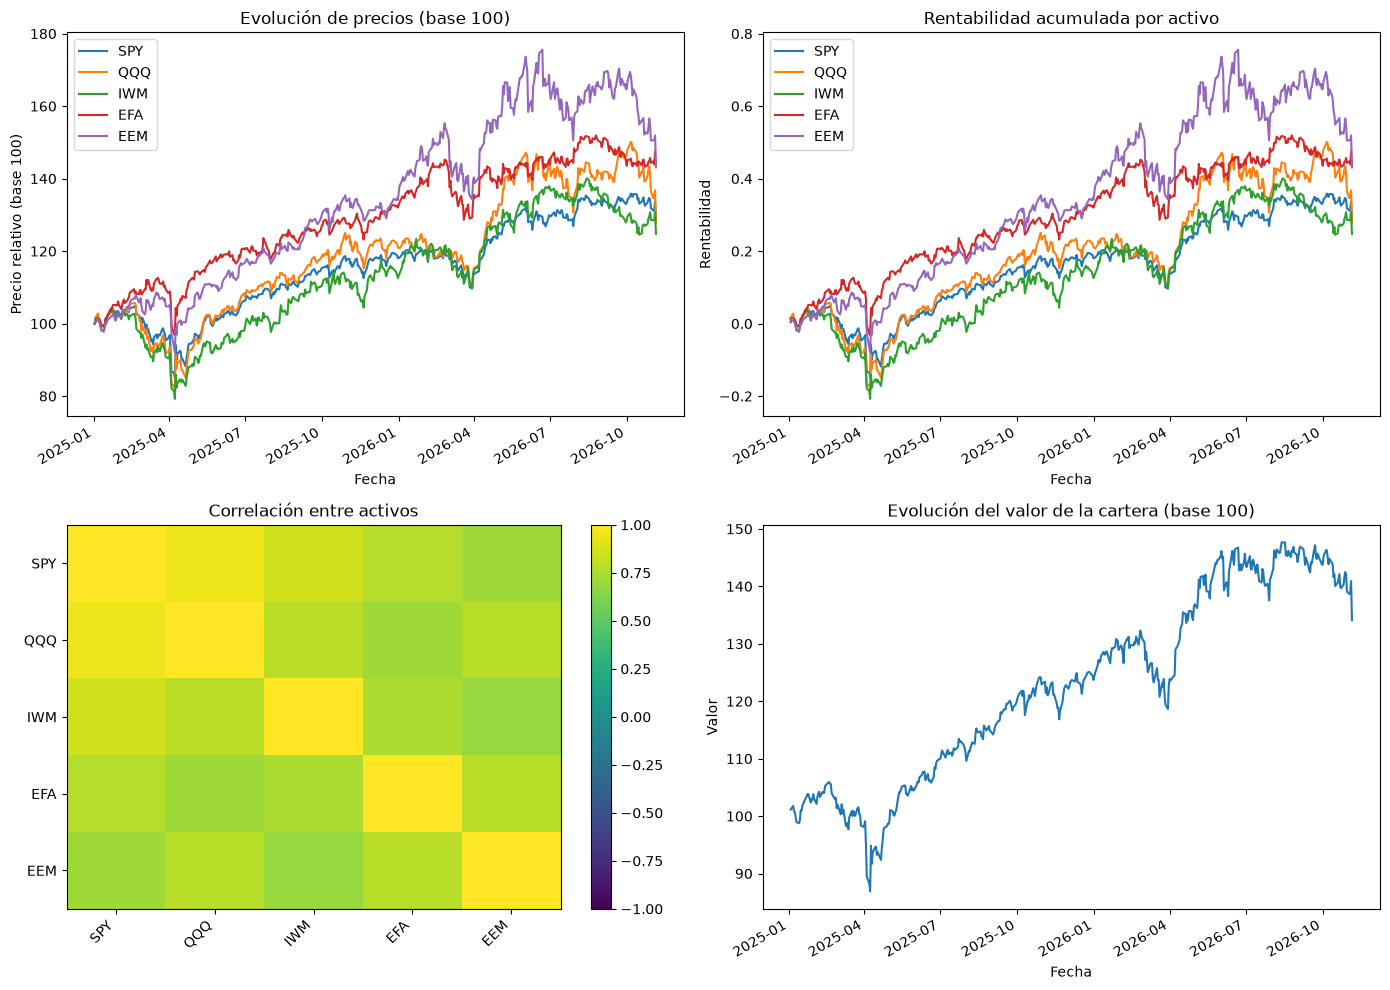

In [5]:
portfolio.plots_report()

## 5 · Simulación Monte Carlo

La simulación usa la deriva y la volatilidad logarítmicas estimadas de la historia. El horizonte
se expresa en los mismos periodos que la anualización de la cartera, de modo que el número de
pasos y los supuestos compartan el mismo calendario. La distribución final permite leer el abanico
de resultados, no una predicción puntual.

count     2000.00
mean     11929.98
std       2247.58
min       6637.22
5%        8652.69
50%      11660.43
95%      16232.45
max      20782.64
Name: 252, dtype: float64


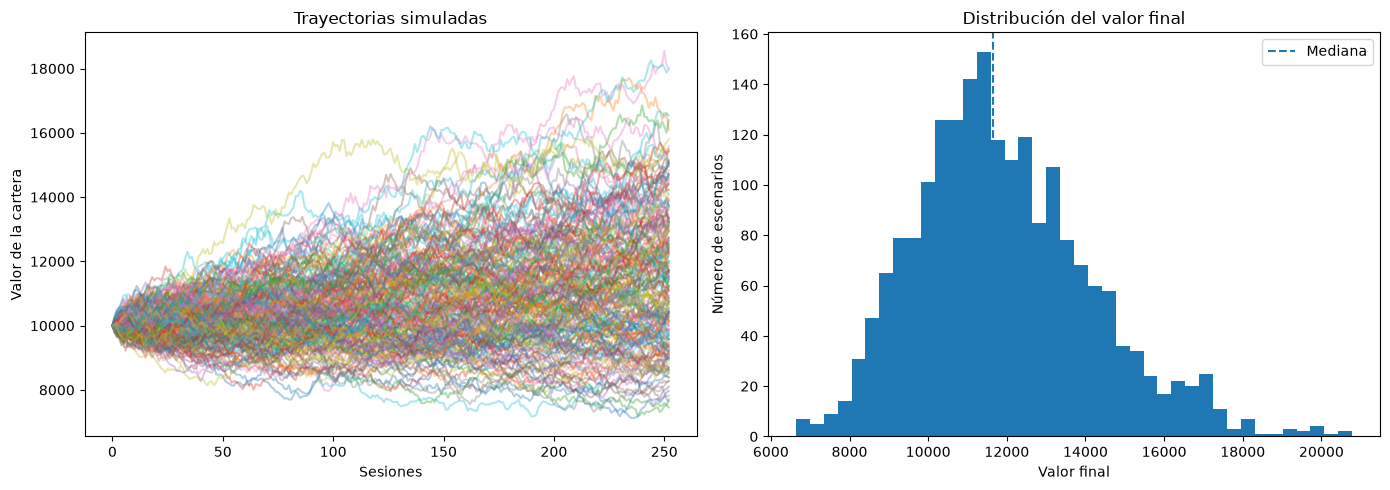

In [6]:
simulations = portfolio.simulate_monte_carlo(
    MonteCarloParameters(
        n_paths=2_000,
        horizon=PERIODS_PER_YEAR,
        periods_per_year=PERIODS_PER_YEAR,
        seed=42,
    )
)

final_values = simulations.iloc[-1]
print(final_values.describe(percentiles=[0.05, 0.5, 0.95]).round(2))
portfolio.plot_simulation(simulations, max_paths=200)

## 6 · Qué aporta esta clase

Los ETF de índices eliminan el riesgo de una sola empresa, pero mantienen el riesgo de mercado, de
tamaño y de región. La correlación entre ETF de renta variable suele ser alta: esta clase diversifica
dentro de la bolsa, no sustituye a la renta fija ni a la cripto como diversificador de una cartera
multi-activo.